In [1]:
import os
import numpy as np
import jax.numpy as jnp
import jax
from scipy import sparse
import time
from jax import grad
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from my_helpers import plot_u_theta, plot_kh
from functools import partial
from Pwp_class import PiecewiseLinearPolynomials

In [2]:
# Utility function to compute L2 norm of a pytree
def pytree_l2_norm(pytree):
    leaves = tree_leaves(pytree)
    return jnp.sqrt(sum(jnp.sum(leaf**2) for leaf in leaves))

In [3]:
# Optimizer Class
class MinMaxOptProb:
    def __init__(self, N_t=10, N_x=10, lr_theta=0.01, hidden_dims=(64, 64, 64), seed=0, sigma=0.1, N_perturb=5000, N_bc=100, N_ic=100,
                 t_min=0, t_max=1, x_min=0, x_max=1, u0=None, u1=None, u2=None, lambda_bc_static=0.99, nu=0.001, alpha_p_coeffs=0):
        self.pwp = PiecewiseLinearPolynomials(N_t, N_x)
        self.lr_theta = lr_theta
        self.model = MLP(hidden_dims=hidden_dims)
        key = jax.random.PRNGKey(seed)
        self.params = self.model.init(key, jnp.ones((1, 2)))['params']
        # Define optimizer
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)
        self.key = jax.random.PRNGKey(seed)
        self.sigma = sigma
        self.N_perturb = N_perturb
        self.N_bc = N_bc
        self.N_ic = N_ic
        # Sample points on each boundary
        self.t_bc = jnp.linspace(t_min, t_max, self.N_bc)  # t values for x=0 and x=1 boundaries
        self.x_bc = jnp.linspace(x_min, x_max, self.N_ic)  # x values for t=0 boundary
        self.u0 = u0
        self.u1 = u1
        self.u2 = u2
        self.lambda_bc_static = lambda_bc_static
        self.nu = nu
        # Adaptive weights for main training
        self.lambda_ic = 1.0
        self.lambda_bc = 1.0  # Renamed to avoid confusion with lambda_bc
        self.lambda_r = 1.0
        self.alpha = 0.9  # Moving average parameter
        self.alpha_p_coeffs = alpha_p_coeffs # Moving average parameter for k_h
        
    def compute_res_visc(self, u_quad, u_t, u_x, u_xx):
        return u_t + u_quad * u_x - self.nu*u_xx
        # return u_t + 0.3*u_x - self.nu*u_xx

    def compute_res(self, u_quad, u_t, u_x):
        return u_t + u_quad * u_x  
        # return u_t + 0.3*u_x

    def compute_loss_opt_kh_element(self, tri_idx, p_coeffs_all, params):
        """
        Compute losses for all perturbations on a single triangle, compatible with jax.vmap.
    
        Args:
            tri_idx: Index of the triangle.
            p_coeffs_all: Array of shape (N_perturb, 3) of perturbed coefficients.
        Returns:
            losses: Array of shape (N_perturb,) containing loss values for each perturbation.
        """
        # Retrieve precomputed quadrature points and weights
        quad_points = self.pwp.quad_points_tri[tri_idx]  # Shape: (Nq, 2)
        quad_weights = self.pwp.quad_weights_tri[tri_idx]  # Shape: (Nq,)
    
        # Evaluate the neural network and its gradients once for the triangle
        u_quad =self.model.apply({'params': params}, quad_points)  # Shape: (Nq,)
        grad_u = jax.vmap(jax.grad(lambda tx: self.model.apply({'params': params}, tx).squeeze()))(quad_points)  # Shape: (Nq, 2)
        u_t, u_x = grad_u[:, 0], grad_u[:, 1]  # Shapes: (Nq,), (Nq,)
    
        # Compute residual (e.g., u_t + u * u_x), fixed for all perturbations
        residual = self.compute_res(u_quad, u_t, u_x)  # Shape: (Nq,)
    
        # Compute k_h for all perturbations at once
        k_h_quad_all = (
            p_coeffs_all[:, 0][:, None] + 
            p_coeffs_all[:, 1][:, None] * quad_points[:, 0] + 
            p_coeffs_all[:, 2][:, None] * quad_points[:, 1]
        )  # Shape: (N_perturb, Nq)
    
        # Compute integrand for all perturbations using broadcasting
        integrand_all = residual[None, :] * jnp.sign(u_quad[None, :] - k_h_quad_all)  # Shape: (N_perturb, Nq)
    
        # Compute losses by summing over quadrature points for each perturbation
        losses = jnp.sum(quad_weights[None, :] * integrand_all, axis=1)  # Shape: (N_perturb,)
        return losses

    def maximize_kh_vec(self, params, current_key):
        Nt = self.pwp.N_elements
        vertices_all = self.pwp.triangles  # Shape: (Nt, 3, 2)
        
        # Evaluate model on all vertices
        u_values_all = self.model.apply({'params': params}, vertices_all)
        
        # Compute initial coefficients
        A_all = jnp.stack([jnp.ones((Nt, 3)), vertices_all[:, :, 0], vertices_all[:, :, 1]], axis=-1)
        initial_coeffs_all = jnp.linalg.solve(A_all, u_values_all[..., None]).squeeze(-1)
        # print(jnp.einsum('ijk,ik->ij', A_all, initial_coeffs_all)-u_values_all)
    
        # Generate perturbations
        key, current_key = jax.random.split(current_key)
        keys = jax.random.split(key, Nt)
        perturbations_all = jax.vmap(lambda k: self.sigma * jax.random.normal(k, (self.N_perturb, 3)))(keys)
        perturbed_coeffs_all = initial_coeffs_all[:, None, :] + perturbations_all
        # print(perturbed_coeffs_all.shape)
        # Compute losses (assuming compute_loss_tri is defined)
        losses_all = jax.vmap(lambda tri_idx, p_coeffs: 
                              self.compute_loss_opt_kh_element(tri_idx, p_coeffs, params))(jnp.arange(Nt), perturbed_coeffs_all)
        # print(losses_all.shape)
        # Select best coefficients
        best_indices = jnp.argmax(losses_all, axis=1)
        best_coeffs_all = perturbed_coeffs_all[jnp.arange(Nt), best_indices]
        # print(f"The max. of optimized coef. for k_h: {jnp.max(jnp.linalg.norm(best_coeffs_all[:,1:]))}")
        return best_coeffs_all, current_key

    def compute_loss_opt_utheta_int(self, params, p_coeffs):
        # Get quadrature points and weights for this triangle
        quad_points = self.pwp.quad_points  # Shape: (Nt*Nq, 2)
        quad_weights = self.pwp.quad_weights  # Shape: (Nt*Nq,)
    
        # Evaluate neural network and its gradients at quadrature points
        u_quad = self.model.apply({'params': params}, quad_points)  # Shape: (Nt*Nq,)
        grad_u = jax.vmap(jax.grad(lambda tx: self.model.apply({'params': params}, tx).squeeze()))(quad_points)  # Shape: (Nt*Nq, 2)
        u_t, u_x = grad_u[:, 0], grad_u[:, 1]  # Shapes: (Nt*Nq,), (Nt*Nq,)
    
        # Compute the residual (example: u_t + u * u_x for a simple PDE)
        residual = self.compute_res(u_quad, u_t, u_x)  # Shape: (Nt*Nq,)
    
        # Compute k_h at quadrature points using the element's coefficients
        p_coeffs_quad = p_coeffs[self.pwp.element_indices]  # Shape: (Nt*Nq,)
        # print(f"p_coeffs_quad shape: {p_coeffs_quad.shape}")
        k_h_quad = p_coeffs_quad[:, 0] + p_coeffs_quad[:, 1] * quad_points[:, 0] + p_coeffs_quad[:, 2] * quad_points[:, 1]  # Shape: (Nt*Nq,)

        # Define the integrand for the loss (residual * sign(u - k_h))
        integrand = residual * jnp.sign(u_quad - k_h_quad)  # Shape: (Nt*Nq,)
        interior_loss = jnp.sum(quad_weights * integrand)  # Scalar
        return interior_loss
        
    def compute_loss_opt_utheta_bc(self, params):
        return self.compute_L_ic(params) + self.compute_L_bc(params)

    def compute_loss_opt_utheta_adaptive(self, params, p_coeffs, lambda_ic, lambda_bc, lambda_r):
        """Compute total loss with adaptive weights."""
        L_ic = self.compute_L_ic(params)
        L_bc = self.compute_L_bc(params)
        L_r = self.compute_loss_opt_utheta_int(params, p_coeffs)
        total_loss = (lambda_ic * L_ic + 
                      lambda_bc * L_bc + 
                      lambda_r * L_r)
        return total_loss
        
    def compute_loss_opt_utheta(self, params, p_coeffs):
        # --- Total Loss ---
        interior_loss = self.compute_loss_opt_utheta_int(params, p_coeffs)
        boundary_loss = self.compute_loss_opt_utheta_bc(params)
        total_loss = (1-self.lambda_bc_static) * interior_loss + self.lambda_bc_static * boundary_loss
        return total_loss

    # def test_u_theta_loss(self, params):
    #     u_quad = self.model.apply({'params': params}, self.pwp.quad_points)
    #     residual = u_quad - jnp.sin(2*(2*jnp.pi*self.pwp.quad_points[:, 0] + self.pwp.quad_points[:, 1]))
    #     loss = jnp.sum(residual**2 * self.pwp.quad_weights)
    #     return loss

    def minimize_u_theta(self, params, p_coeffs, opt_state_theta):
        loss_value, grad_params = jax.value_and_grad(self.compute_loss_opt_utheta, argnums=0)(params, p_coeffs)
        # loss_value, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta

    def minimize_u_theta_adaptive(self, params, p_coeffs, opt_state_theta, lambda_ic, lambda_bc, lambda_r):
        """Minimize u_theta with adaptive weights."""
        loss_value, grad_params = jax.value_and_grad(self.compute_loss_opt_utheta_adaptive, argnums=0)(params, p_coeffs, lambda_ic, 
                                                                                                       lambda_bc, lambda_r)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta

    def pre_train_compute_loss_opt_utheta_int(self, params):
        # Get quadrature points and weights for this triangle
        quad_points = self.pwp.quad_points  # Shape: (Nt*Nq, 2)
        quad_weights = self.pwp.quad_weights  # Shape: (Nt*Nq,)
    
        # Evaluate neural network and its gradients at quadrature points
        u_quad = self.model.apply({'params': params}, quad_points)  # Shape: (Nt*Nq,)
        grad_u = jax.vmap(jax.grad(lambda tx: self.model.apply({'params': params}, tx).squeeze()))(quad_points)  # Shape: (Nt*Nq, 2)
        u_t, u_x = grad_u[:, 0], grad_u[:, 1]  # Shapes: (Nt*Nq,), (Nt*Nq,)
        # Compute Hessian
        hessian_u = jax.hessian(lambda tx: self.model.apply({'params': params}, tx).squeeze())
        hessians = jax.vmap(hessian_u)(quad_points)  # Shape: (Nt*Nq, 2, 2)
        u_xx = hessians[:, 1, 1]  # Shape: (Nt*Nq,), second derivative w.r.t. x
    
        # Compute the residual (example: u_t + u * u_x for a simple PDE)
        residual = self.compute_res_visc(u_quad, u_t, u_x, u_xx)  # Shape: (Nt*Nq,)
        integrand = residual**2
        interior_loss = jnp.sum(quad_weights * integrand)  # Scalar
        return interior_loss

    # def pre_train_compute_loss_opt_utheta(self, params):
    #     interior_loss = self.pre_train_compute_loss_opt_utheta_int(params)
    #     boundary_loss = self.compute_loss_opt_utheta_bc(params)
    #     total_loss = (1-self.lambda_bc_static) * interior_loss + self.lambda_bc_static * boundary_loss
    #     return total_loss

    def pre_train_compute_loss_opt_utheta_adaptive(self, params, lambda_ic=0, lambda_bc=0, lambda_r=1):
        L_ic = self.compute_L_ic(params)
        L_bc = self.compute_L_bc(params)
        L_r = self.pre_train_compute_loss_opt_utheta_int(params)
        total_loss = (lambda_ic * L_ic + 
                      lambda_bc * L_bc + 
                      lambda_r * L_r)
        return total_loss

    def pre_train_minimize_u_theta(self, params, opt_state_theta):
        loss_value, grad_params = jax.value_and_grad(self.pre_train_compute_loss_opt_utheta)(params)
        # loss_value, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta

    def pre_train_minimize_u_theta_adaptive(self, params, opt_state_theta, lambda_ic=0, lambda_bc=0, lambda_r=1):
        loss_value, grad_params = jax.value_and_grad(self.pre_train_compute_loss_opt_utheta_adaptive, argnums=0)(params,
                                                                                                    lambda_ic, lambda_bc, lambda_r)
        # loss_value, grad_params = jax.value_and_grad(self.test_u_theta_loss)(params)
        updates, opt_state_theta = self.opt_theta.update(grad_params, opt_state_theta)
        params = optax.apply_updates(params, updates)
        return loss_value, params, opt_state_theta

    def pre_train_step(self, iter):
        if iter % 200 == 0:
            self.update_adaptive_weights(self.params, self.pwp.coeffs, phase='pre-train')
            print(f"Iteration {iter}, lambda_ic: {self.lambda_ic}, lambda_bc: {self.lambda_bc}, lambda_r: {self.lambda_r}.")
        minimize_u_theta = jax.jit(self.pre_train_minimize_u_theta_adaptive)
        # pre_train_minimize_u_theta = self.pre_train_minimize_u_theta
        loss_value, self.params, self.opt_state_theta = minimize_u_theta(self.params, self.opt_state_theta,
                                                                         self.lambda_ic, self.lambda_bc, self.lambda_r)
        # return self.compute_loss_opt_utheta(self.params)
        return self.pre_train_compute_loss_opt_utheta_int(self.params), self.compute_loss_opt_utheta_bc(self.params)
        
    def pre_train_process(self, pre_train_num_iterations, save_loss=True, save_model=True):
        print("\nStarting Pre-Train Stage")
        start_time = time.perf_counter()
        self.lambda_ic = 1.0
        self.lambda_bc = 1.0
        self.lambda_r = 1.0
        self.pre_loss_int_history = []
        self.pre_loss_bc_history = []
        for iter in range(pre_train_num_iterations):
            loss_int, loss_bc = self.pre_train_step(iter)
            self.pre_loss_int_history.append(loss_int)
            self.pre_loss_bc_history.append(loss_bc)
            if iter % 10 == 0:
                print(f"Pre-train Iteration {iter}, Loss_int: {loss_int:.8f}, Loss_bc: {loss_bc:.8f}")
        end_time = time.perf_counter()
        pre_train_total_time = end_time - start_time
        print(f"Pre-train total time: {pre_train_total_time:.8f} seconds")
        print(f"Pre-train average time per iteration: {pre_train_total_time / pre_train_num_iterations:.9e} seconds")
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        if save_loss:
            # Save training loss histories with consistent naming
            loss_int_path = os.path.join('..', 'data', f'pre_train_loss_int_history_{timestamp}.pkl')
            with open(loss_int_path, 'wb') as f:
                pickle.dump(self.pre_loss_int_history, f)
            loss_bc_path = os.path.join('..', 'data', f'pre_train_loss_bc_history_{timestamp}.pkl')
            with open(loss_bc_path, 'wb') as f:
                pickle.dump(self.pre_loss_bc_history, f)
            print(f"Pre-train loss histories saved to {loss_int_path} and {loss_bc_path}")
        
        if save_model:
            # Save both params and architecture info
            model_path = os.path.join('..', 'data', f'pre_train_model_{timestamp}.pkl')
            self.save_model(model_path)
            print(f"Pre-train model saved to {model_path}")
                

    # --- Define Individual Loss Components ---
    def compute_L_ic(self, params):
        """Compute initial condition loss L_ic."""
        tx_t0 = jnp.stack([jnp.zeros_like(self.x_bc), self.x_bc], axis=1)
        u_t0 = self.model.apply({'params': params}, tx_t0)
        return jnp.mean((u_t0 - self.u0(self.x_bc))**2)

    def compute_L_bc(self, params):
        """Compute boundary condition loss L_bc."""
        # Boundary at x=-1
        tx_x0 = jnp.stack([self.t_bc, -jnp.ones_like(self.t_bc)], axis=1)
        u_x0 = self.model.apply({'params': params}, tx_x0)
        bc_x0_loss = jnp.mean((u_x0 - self.u1(self.t_bc))**2)
        # Boundary at x=1
        tx_x1 = jnp.stack([self.t_bc, jnp.ones_like(self.t_bc)], axis=1)
        u_x1 = self.model.apply({'params': params}, tx_x1)
        bc_x1_loss = jnp.mean((u_x1 - self.u2(self.t_bc))**2)
        return bc_x0_loss + bc_x1_loss

    # --- Adaptive Weight Update ---
    def update_adaptive_weights(self, params, p_coeffs, phase='pre-train'):
        """Update lambda_ic, lambda_bc, and lambda_r every 10 iterations."""
        # Compute gradients
        grad_L_ic = grad(self.compute_L_ic)(params)
        grad_L_bc = grad(self.compute_L_bc)(params)
        if phase=='pre-train':
            grad_L_r = grad(lambda p: self.pre_train_compute_loss_opt_utheta_int(p))(params)
        elif phase=='train':
            grad_L_r = grad(lambda p: self.compute_loss_opt_utheta_int(p, p_coeffs))(params)

        # Compute L2 norms
        norm_ic = pytree_l2_norm(grad_L_ic)
        norm_bc = pytree_l2_norm(grad_L_bc)
        norm_r = pytree_l2_norm(grad_L_r)

        # Sum of norms with epsilon to avoid division by zero
        epsilon = 1e-7
        sum_norm = norm_ic + norm_bc + norm_r + epsilon

        # Compute hat_lambda values
        hat_lambda_ic = jnp.clip(sum_norm / (norm_ic + epsilon), a_min=1, a_max=1e7)
        hat_lambda_bc = jnp.clip(sum_norm / (norm_bc + epsilon), a_min=1, a_max=1e7)
        hat_lambda_r = jnp.clip(sum_norm / (norm_r + epsilon), a_min=1, a_max=1e7)

        # Update weights using moving average
        self.lambda_ic = self.alpha * self.lambda_ic + (1 - self.alpha) * hat_lambda_ic
        self.lambda_bc = self.alpha * self.lambda_bc + (1 - self.alpha) * hat_lambda_bc
        self.lambda_r = self.alpha * self.lambda_r + (1 - self.alpha) * hat_lambda_r
    


    def train_step(self, iter, moving_avg=True):
        if iter % 100 == 0:
            self.update_adaptive_weights(self.params, self.pwp.coeffs, phase='train')
            print(f"Iteration {iter}, lambda_ic: {self.lambda_ic:.8f}, lambda_bc: {self.lambda_bc:.8f}, lambda_r: {self.lambda_r:.8f}.")
        # First, we minimize u_theta since k_h has been maximized when loading the model.
        # minimize_u_theta = jax.jit(self.minimize_u_theta)
        # minimize_u_theta = self.minimize_u_theta
        # loss_value, self.params, self.opt_state_theta = minimize_u_theta(self.params, self.pwp.coeffs, self.opt_state_theta)
        minimize_u_theta = jax.jit(self.minimize_u_theta_adaptive)
        loss_value, self.params, self.opt_state_theta = minimize_u_theta(self.params, self.pwp.coeffs, self.opt_state_theta, 
                                                                         self.lambda_ic, self.lambda_bc, self.lambda_r)
        
        # Then we maximize k_h
        maximize_kh_vec = jax.jit(self.maximize_kh_vec)
        # maximize_kh_vec = self.maximize_kh_vec
        if iter % 1 == 0:
            print(f"Iteration {iter}, before maximize k_h, loss: {self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs):.8f}, {self.compute_loss_opt_utheta_bc(self.params):.8f}.")
        hat_coeffs, self.key = maximize_kh_vec(self.params, self.key)
        # Moving average for self.pwp.coeffs
        self.pwp.coeffs = self.alpha_p_coeffs * self.pwp.coeffs + (1 - self.alpha_p_coeffs) * hat_coeffs
        if iter % 1 == 0:
            print(f"Iteration {iter}, after maximize k_h, loss: {self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs):.8f}, {self.compute_loss_opt_utheta_bc(self.params):.8f}.")
        # return self.compute_loss_opt_utheta(self.params)
        return self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs), self.compute_loss_opt_utheta_bc(self.params)

    def train_process(self, train_num_iterations, save_loss=True, save_model=True):
        print("\nStarting Train Stage")
        start_time = time.perf_counter()
        self.lambda_ic = 1.0
        self.lambda_bc = 1.0  # Renamed to avoid confusion with lambda_bc
        self.lambda_r = 1.0
        self.loss_int_history = []
        self.loss_bc_history = []
        for iter in range(train_num_iterations):
            loss_int, loss_bc = self.train_step(iter)
            self.loss_int_history.append(loss_int)
            self.loss_bc_history.append(loss_bc)
            if iter % 10 == 0:
                print(f"Train Iteration {iter}, Loss_int: {loss_int:.8f}, Loss_bc: {loss_bc:.8f}")
        end_time = time.perf_counter()
        train_total_time = (end_time - start_time)
        print(f"Train total time: {train_total_time:.8f} seconds")
        print(f"Train average time per iteration: {train_total_time / train_num_iterations:.9e} seconds")
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        if save_loss:
            # Save training loss histories with consistent naming
            loss_int_path = os.path.join('..', 'data', f'loss_int_history_{timestamp}.pkl')
            with open(loss_int_path, 'wb') as f:
                pickle.dump(self.loss_int_history, f)
            loss_bc_path = os.path.join('..', 'data', f'loss_bc_history_{timestamp}.pkl')
            with open(loss_bc_path, 'wb') as f:
                pickle.dump(self.loss_bc_history, f)
            print(f"Loss histories saved to {loss_int_path} and {loss_bc_path}")
        
        if save_model:
            # Save both params and architecture info
            model_path = os.path.join('..', 'data', f'train_model_{timestamp}.pkl')
            self.save_model(model_path)
            print(f"Train model saved to {model_path}")

    def save_model(self, model_path):
        save_dict = {
            'params': self.params,
            'hidden_dims': self.model.hidden_dims
        }
        with open(model_path, 'wb') as f:
            pickle.dump(save_dict, f)

    def load_model(self, model_path):
        """
        Load the saved model parameters and recreate the architecture.

        Args:
            model_path: Path to the saved model file (e.g., '../data/train_model_20231015_123456.pkl').

        Returns:
            None (updates self.params and self.model)
        """
        with open(model_path, 'rb') as f:
            loaded_data = pickle.load(f)

        # Extract parameters and architecture info
        loaded_params = loaded_data['params']
        loaded_hidden_dims = loaded_data['hidden_dims']

        # Recreate the model with the same architecture
        self.model = MLP(hidden_dims=loaded_hidden_dims)
        
        # Initialize with a dummy key to set up the structure (params will be overwritten)
        key = jax.random.PRNGKey(0)  # Any seed; params will be replaced
        dummy_input = jnp.ones((1, 2))
        self.params = self.model.init(key, dummy_input)['params']

        # Assign the loaded parameters
        self.params = loaded_params

        # Re-initialize optimizer state with loaded params
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)
        print(f"Model loaded from {model_path} with hidden_dims: {loaded_hidden_dims}")
        self.pwp.coeffs, self.key = self.maximize_kh_vec(self.params, self.key)
        loss_int, loss_bc = self.compute_loss_opt_utheta_int(self.params, self.pwp.coeffs), self.compute_loss_opt_utheta_bc(self.params)
        print(f"For the loaded model, Loss_int: {loss_int:.8f}, Loss_bc: {loss_bc:.8f}.")


In [4]:
# eps0 = 1e-4
# def smooth_sign(x, eps = eps0):
#     return 2*jax.nn.sigmoid(x/eps)-1

# Define boundary and initial conditions
def u0(x):
    # return 2*smooth_sign(x) - 1
    return -jnp.sign(x)

# Boundary at x=-1
def u1(x):
    return 1

# Boundary at x=1
def u2(x):
    return -1

# Initialize separate loss history lists for each stage
pre_loss_int_history = []
pre_loss_bc_history = []
train_loss_int_history = []
train_loss_bc_history = []

# Function to plot loss history
def plot_loss_history(loss_int, loss_bc, title):
    plt.figure()
    plt.plot(loss_int, label='Loss Interior')
    plt.plot(loss_bc, label='Loss Boundary')
    plt.xlabel('Iteration')
    plt.ylabel('Loss (log scale)')
    plt.yscale('log')
    plt.grid(True, which="both", ls="--")
    plt.legend()
    plt.title(title)
    plt.show()

# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=16,
    N_x=64,
    lr_theta=0.02,
    N_bc=100,
    N_ic=400,
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
)

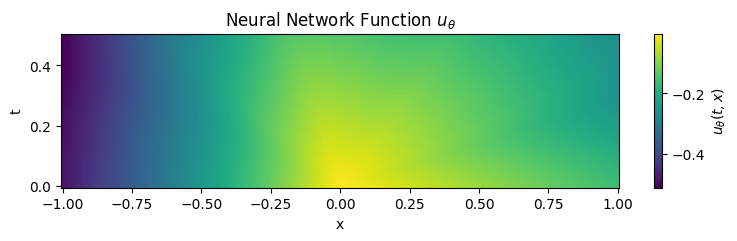


Starting Pre-Train Stage
Iteration 0, lambda_ic: 783.4144897460938, lambda_bc: 194.66867065429688, lambda_r: 1.0000643730163574.
Pre-train Iteration 0, Loss_int: 8521.65722656, Loss_bc: 1.93771362
Pre-train Iteration 10, Loss_int: 47.63698196, Loss_bc: 1.10211241
Pre-train Iteration 20, Loss_int: 131.59349060, Loss_bc: 0.38261846
Pre-train Iteration 30, Loss_int: 93.05776978, Loss_bc: 0.27628070
Pre-train Iteration 40, Loss_int: 85.27034760, Loss_bc: 0.24179555
Pre-train Iteration 50, Loss_int: 66.41959381, Loss_bc: 0.20450316
Pre-train Iteration 60, Loss_int: 156.87026978, Loss_bc: 0.19203065
Pre-train Iteration 70, Loss_int: 67.90962982, Loss_bc: 0.36872867
Pre-train Iteration 80, Loss_int: 84.70998383, Loss_bc: 0.22143318
Pre-train Iteration 90, Loss_int: 49.52642822, Loss_bc: 0.31183755
Pre-train Iteration 100, Loss_int: 61.63222504, Loss_bc: 0.39963716
Pre-train Iteration 110, Loss_int: 78.47758484, Loss_bc: 0.26756209
Pre-train Iteration 120, Loss_int: 63.23117828, Loss_bc: 0.26

KeyboardInterrupt: 

In [5]:
# Pre-train stage
pre_train_num_iterations = 2000
plot_u_theta(optProb.model, optProb.params, M_t=50, M_x=200, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0)  # Plot initial model state
optProb.pre_train_process(pre_train_num_iterations)
plot_u_theta(optProb.model, optProb.params, M_t=50, M_x=200, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0)  # Plot after pre-train

# Plot pre-train loss history
plot_loss_history(optProb.pre_loss_int_history, optProb.pre_loss_bc_history, 'Pre-train Loss History')


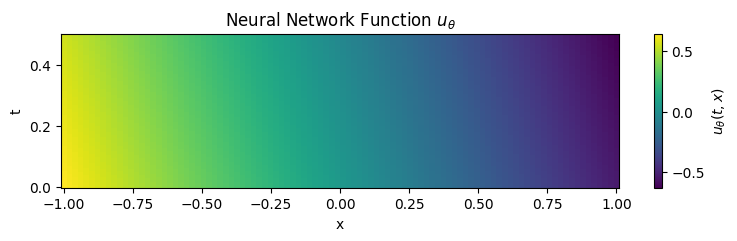

In [6]:
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0)  # Plot after pre-train


In [ ]:
optProb = MinMaxOptProb(
    N_t=32,
    N_x=32,
    lr_theta=0.001,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
)
optProb.load_model('../data/pre_train_model_20250402_162344.pkl')

# Train stage
train_num_iterations = 2000

plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)  # Plot before train
optProb.train_process(train_num_iterations)
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)  # Plot after train

# Plot train loss history
plot_loss_history(optProb.loss_int_history, optProb.loss_bc_history, 'Train Loss History')

In [ ]:
plot_loss_history(optProb.loss_int_history, optProb.loss_bc_history, 'Train Loss History')

In [ ]:
# This is a training without pre-training!
optProb = MinMaxOptProb(
    N_t=32,
    N_x=32,
    lr_theta=0.001,
    hidden_dims=(64, 64, 64, 64),
    seed=0,
    u0=u0, u1=u1, u2=u2,
    alpha_p_coeffs=0,
)

# Train stage
train_num_iterations = 4000

plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)  # Plot before train
optProb.train_process(train_num_iterations)
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)  # Plot after train

# Plot train loss history
plot_loss_history(optProb.loss_int_history, optProb.loss_bc_history, 'Train Loss History')

In [ ]:
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)

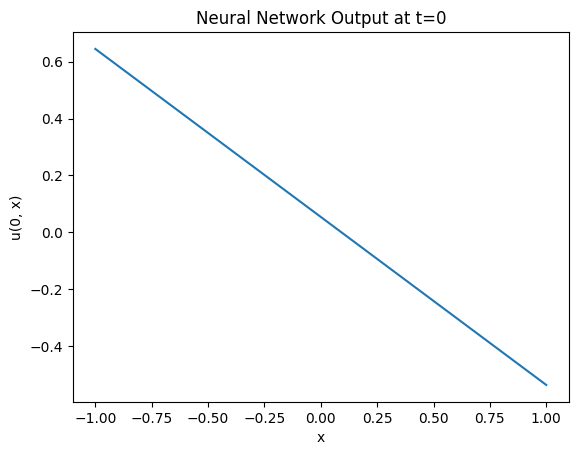

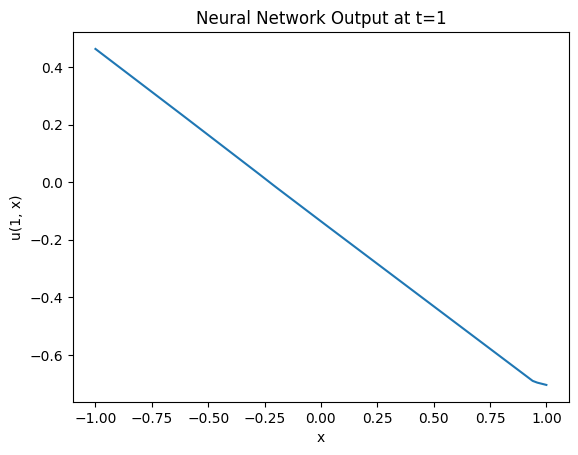

In [8]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def plot_at_t1(predict_fn, x_range=(0, 1), num_points=100, filename='plot.eps'):
    """
    Plot the neural network output at t=1 over a range of x values and save as .eps.

    Args:
        predict_fn: A callable that takes a batch of [t, x] inputs and returns outputs.
                    Example: lambda inputs: model.apply({'params': params}, inputs)
        x_range: Tuple (x_min, x_max) specifying the range of x values. Default is (0, 1).
        num_points: Number of points to evaluate and plot. Default is 100.
        filename: Name of the file to save the plot, including '.eps' extension. Default is 'plot.eps'.
    """
    # Generate x values over the specified range
    x = jnp.linspace(x_range[0], x_range[1], num_points)
    
    # Create inputs with t=1 and varying x
    t0 = jnp.zeros_like(x) * 1.0
    inputs0 = jnp.stack([t0, x], axis=1)  # Shape: (num_points, 2)
    t1 = jnp.ones_like(x) * 1.0
    inputs1 = jnp.stack([t1, x], axis=1)  # Shape: (num_points, 2)
    
    # Evaluate the neural network on the inputs
    outputs0 = predict_fn(inputs0)  # Shape: (num_points,)
    outputs1 = predict_fn(inputs1)  # Shape: (num_points,)
    
    # Create the plot
    plt.figure()
    plt.plot(x, outputs0)
    plt.xlabel('x')
    plt.ylabel('u(0, x)')
    plt.title('Neural Network Output at t=0')

    plt.figure()
    plt.plot(x, outputs1)
    plt.xlabel('x')
    plt.ylabel('u(1, x)')
    plt.title('Neural Network Output at t=1')
    
    # Save the plot in .eps format
    # plt.savefig(filename, format='eps')
    # plt.close()  # Close the figure to free memory
# Assuming 'model' and 'params' are defined (e.g., from a Flax neural network)
predict_fn = lambda inputs: optProb.model.apply({'params': optProb.params}, inputs)

# Call the plotting function
plot_at_t1(predict_fn, x_range=(-1, 1), filename='output_at_t1.eps')

In [ ]:
import matplotlib.pyplot as plt

def u0(x):
    # return 2*smooth_sign(x) - 1
    return -0.5*(jnp.sign(x) - 1)
xx = np.linspace(-1,1,100)
yy = u0(xx)

plt.plot(xx, yy)

In [ ]:
-jnp.ones_like(jnp.ones(10))